In [1]:
import sys
lib_path = '/home/jovyan/libs'
sys.path.insert(0, lib_path)

In [2]:
import torch
from utils import audio, attention

from datasets import load_from_disk

In [3]:
dataset = load_from_disk("/home/jovyan/tedlium/validation.hf").with_format("torch").select(range(100))

In [15]:
model, processor = attention.init()

In [5]:
print(dataset[10])

{'audio': tensor([ 0.0033,  0.0018,  0.0003,  ...,  0.0005, -0.0027, -0.0020]), 'text': 'if they get surrounded they notice that too they might get a little flustered and they can also sense their motion and tilt'}


In [6]:
example = dataset[10]["audio"]

"""
Promising examples: 2, 3, 4, 10

Not promising examples: 1
""";

In [7]:
encoder_limit = int(example.size(0) / 16000 * 50) + 1
encoder_limit

466

In [8]:
audio.play_audio(example)

In [9]:
_, _, _, e_attns, _, _ = attention.inference(example, model, processor, skip_special_tokens=True)

/home/jovyan/libs/_distutils_hack/__init__.py:54: UserWarning: Reliance on distutils from stdlib is deprecated. Users must rely on setuptools to provide the distutils module. Avoid importing distutils or import setuptools first, and avoid setting SETUPTOOLS_USE_DISTUTILS=stdlib. Register concerns at https://github.com/pypa/setuptools/issues/new?template=distutils-deprecation.yml
  warnings.warn(
WhisperModel is using WhisperSdpaAttention, but `torch.nn.functional.scaled_dot_product_attention` does not support `output_attentions=True` or `layer_head_mask` not None. Falling back to the manual attention implementation, but specifying the manual implementation will be required from Transformers version v5.0.0 onwards. This warning can be removed using the argument `attn_implementation="eager"` when loading the model.


In [10]:
# filename = None

# encoded_filename = None if not filename else filename + "_cross.png"
# cross_truncated_filename = None if not filename else filename + "_cross_truncated.png"

# Encoder Attentions

In [11]:
e_attns_stacked_cutoff = torch.stack(e_attns).squeeze()[:, :, :encoder_limit, :encoder_limit]

100% 24/24 [02:46<00:00,  6.92s/it]


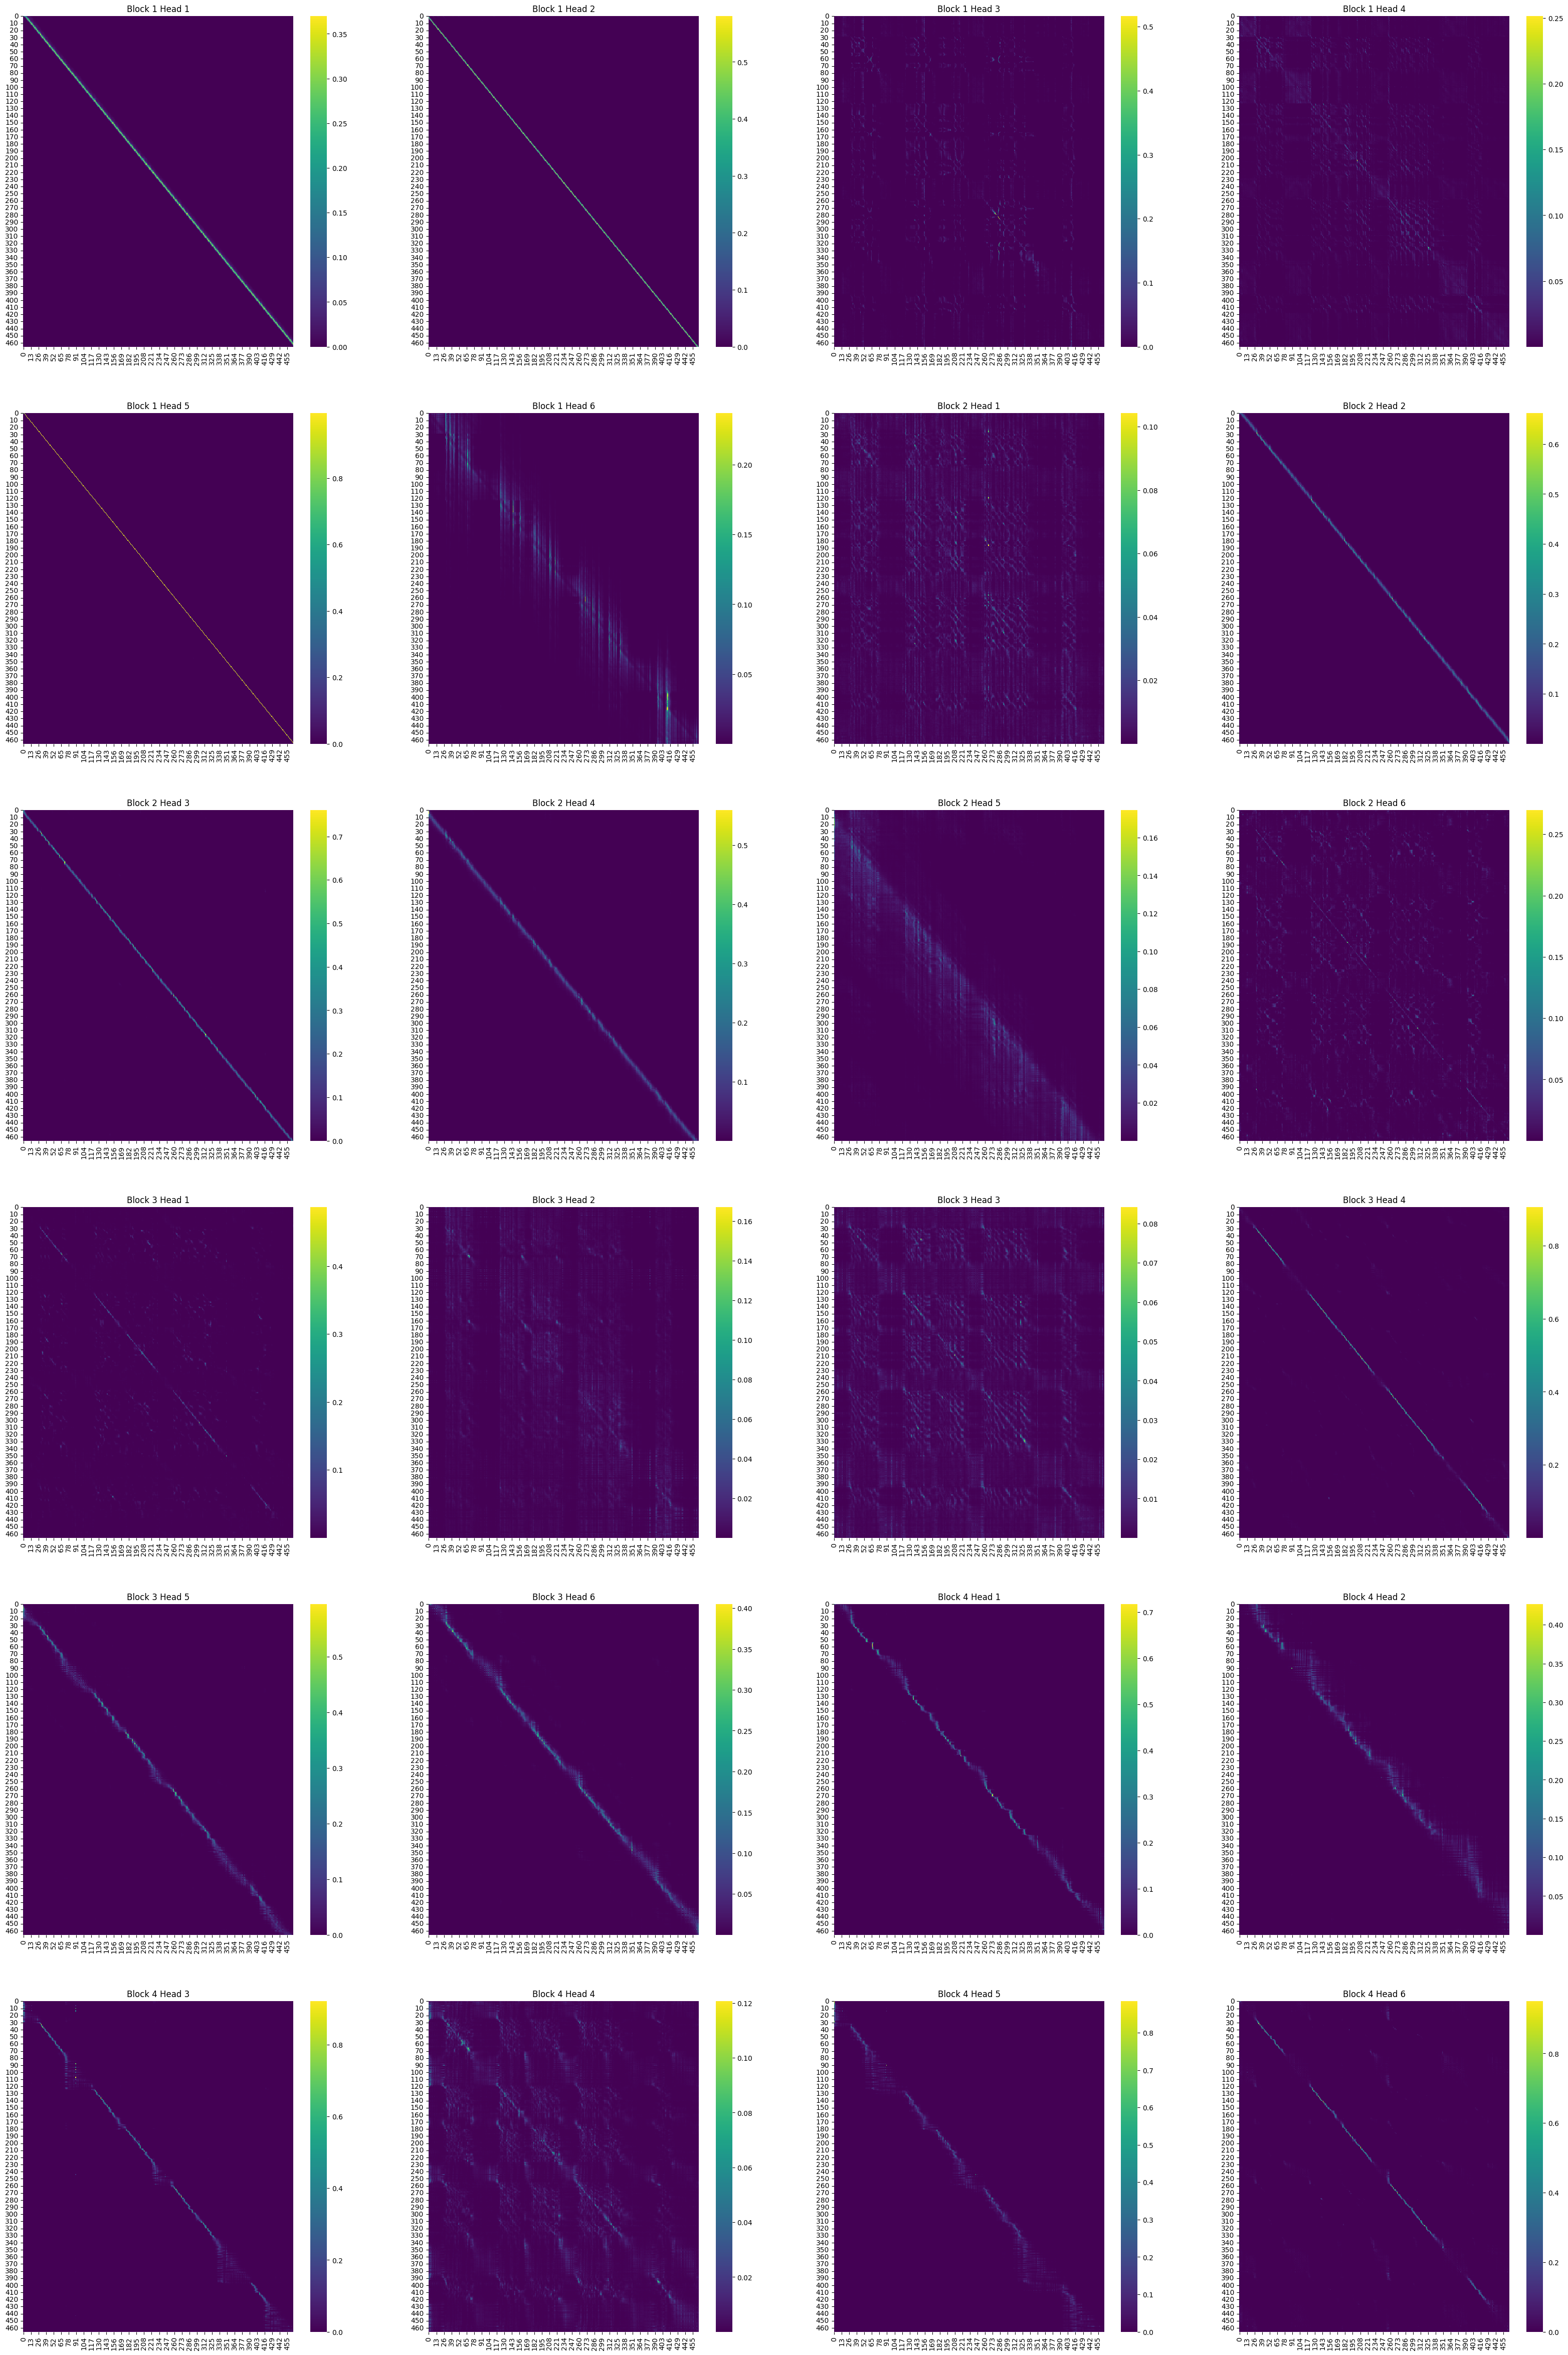

In [12]:
attention.plot_attns(e_attns_stacked_cutoff, 6, 4)

Indices: [32, 63, 270, 275, 276, 277, 278, 279, 282, 283, 284, 285]


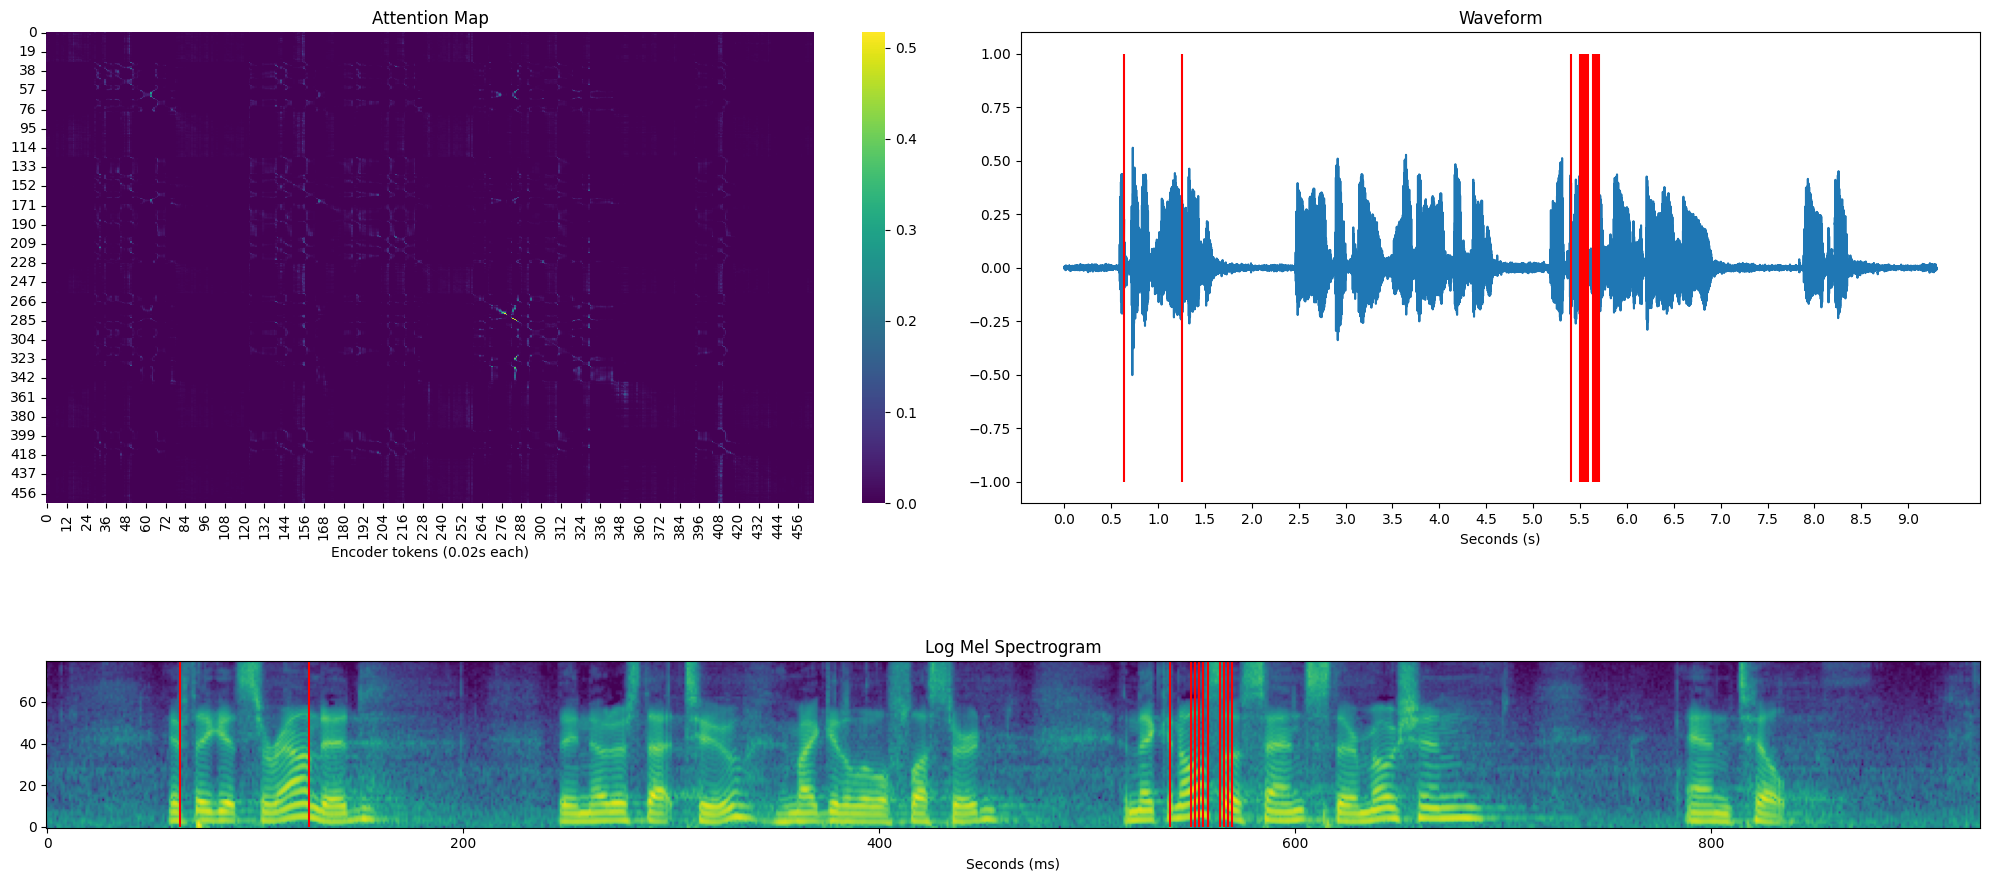

In [13]:
attention.plot_spikes(example, e_attns_stacked_cutoff[0, 2], 0.4, figsize=(20, 10))

In [14]:
audio.play_audio(example[43:])